CAS 1: dt = dx^2
Nombre de passos: 250
dt = 0.0001
Error maxim = 2.0378178738900132e-06
Error quadratic mitja = 1.5557458520510535e-06

CAS 2: dt = 0.5*dx^2
Nombre de passos: 500
dt = 5e-05
Error maxim = 2.043277845475977e-06
Error quadratic mitja = 1.5582642567992096e-06


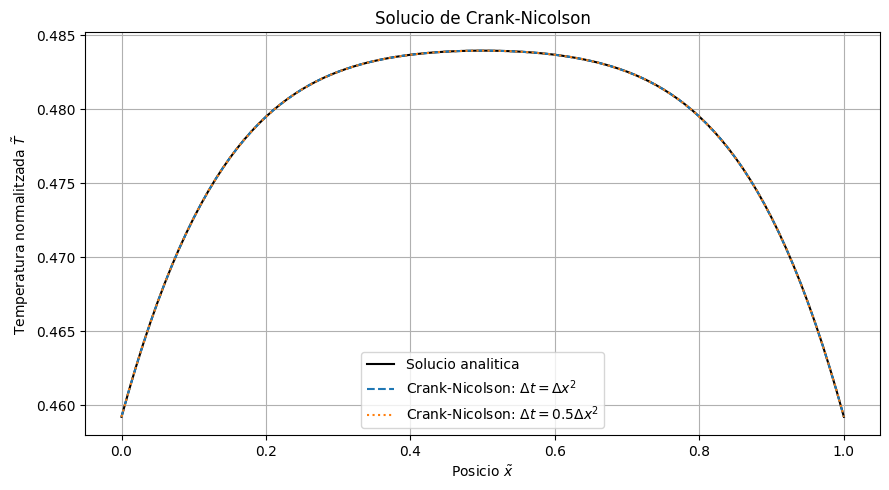

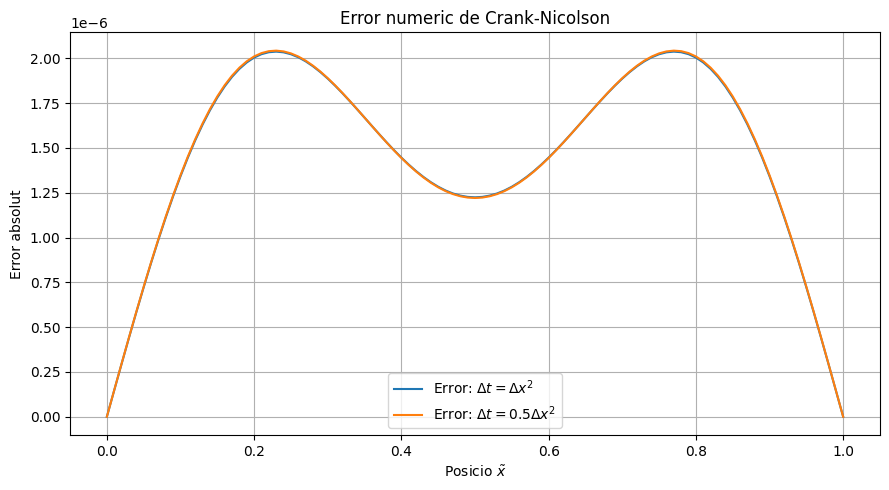

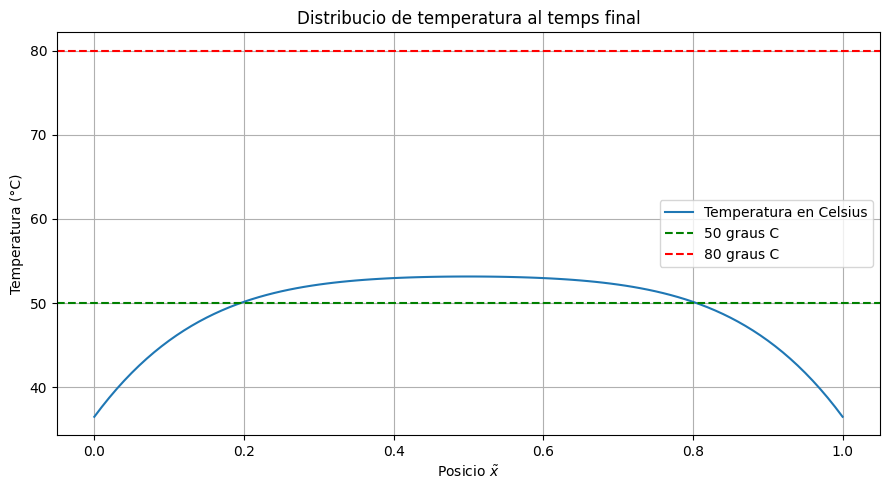

In [1]:
#Crank-Nicolson

# Importem les llibreries necessaries
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve


# Definim els parametres del problema


N = 101
xa = 1.0
ta = 0.025

dx = xa / (N - 1)
x = np.linspace(0, xa, N)

# Temperatura inicial i escala de temperatura
Tc = 36.5 + 273.15       # K
T0 = 674.286             # K
beta = Tc / T0

# Nombre de termes de la serie de Fourier
n_terms = 1000


# Definim la nostra solucio analitica

def sol_analitica(x, t):
    beta = (36.5 + 273.15) / 674.286

    T = np.full_like(x, beta, dtype=float)

    for n in range(1, 2000, 2):

        bn = 4 / (n * np.pi)

        T += bn * ((1 - np.exp(-n**2 * np.pi**2 * t))
                   / (n**2 * np.pi**2)) * np.sin(n * np.pi * x)

    return T


# Apliquem el mètode de Crank-Nicolson


def crank_nicolson(dt):

    # Nombre de passos temporals
    Nt = round(ta / dt)

    # Ajustem dt per arribar exactament a ta
    dt = ta / Nt

    r = dt / dx**2

    # Condicio inicial: increment de temperatura (respecte de la temperatura corporal)
    theta = np.zeros(N)

    # Contstruim la matriu A: diagonal principal 1+r i diagonals secundaries -r/2
    A = np.diag((1 + r) * np.ones(N-2))
    A += np.diag((-r/2) * np.ones(N-3), 1)
    A += np.diag((-r/2) * np.ones(N-3), -1)

    # Contruim la matriu B: diagonal principal 1-r i diagonals secundaries r/2
    B = np.diag((1 - r) * np.ones(N-2))
    B += np.diag((r/2) * np.ones(N-3), 1)
    B += np.diag((r/2) * np.ones(N-3), -1)

    # Factoritzacio LU de A (es calcula una sola vegada)
    LU = lu_factor(A)

    # Evolucio temporal
    for k in range(Nt):

        # Definim el terme independent
        b = B @ theta[1:-1] + dt * np.ones(N-2)

        # Resolem el sistema lineal
        theta[1:-1] = lu_solve(LU, b)

    # Recuperem la temperatura normalitzada absoluta
    T = theta + beta

    return T, theta, Nt, dt



# Passem a la resolucio dels dos casos amb els respectius dt


dt1 = dx**2
dt2 = 0.5 * dx**2

T1, theta1, Nt1, dt1 = crank_nicolson(dt1)
T2, theta2, Nt2, dt2 = crank_nicolson(dt2)

# Solucio analitica al temps final
T_exacta = sol_analitica(x, ta)


# Calculem els diferents errors de cada cas


error1 = np.abs(T1 - T_exacta)
error2 = np.abs(T2 - T_exacta)

# Error maxim
error_max1 = np.max(error1)
error_max2 = np.max(error2)

# Error quadratic mitja
error_mitja1 = np.sqrt(np.mean(error1**2))
error_mitja2 = np.sqrt(np.mean(error2**2))

# Mostrem els errors de cada cas
print("CAS 1: dt = dx^2")
print("Nombre de passos:", Nt1)
print("dt =", dt1)
print("Error maxim =", error_max1)
print("Error quadratic mitja =", error_mitja1)

print("\nCAS 2: dt = 0.5*dx^2")
print("Nombre de passos:", Nt2)
print("dt =", dt2)
print("Error maxim =", error_max2)
print("Error quadratic mitja =", error_mitja2)



# Representem les solucions


plt.figure(figsize=(9, 5))

plt.plot(x, T_exacta, 'k-', label='Solucio analitica')
plt.plot(x, T1, '--', label=r'Crank-Nicolson: $\Delta t=\Delta x^2$')
plt.plot(x, T2, ':', label=r'Crank-Nicolson: $\Delta t=0.5\Delta x^2$')

plt.xlabel(r'Posicio $\tilde{x}$')
plt.ylabel(r'Temperatura normalitzada $\tilde{T}$')
plt.title('Solucio de Crank-Nicolson')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()



# Representem els errors


plt.figure(figsize=(9, 5))

plt.plot(x, error1, label=r'Error: $\Delta t=\Delta x^2$')
plt.plot(x, error2, label=r'Error: $\Delta t=0.5\Delta x^2$')

plt.xlabel(r'Posicio $\tilde{x}$')
plt.ylabel('Error absolut')
plt.title('Error numeric de Crank-Nicolson')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()



# Expressem la temperaura en graus celcius


T_celsius = Tc + T0 * theta2 - 273.15

plt.figure(figsize=(9, 5))

plt.plot(x, T_celsius, label='Temperatura en Celsius')

plt.axhline(50, color='green', linestyle='--',
            label='50 graus C')
plt.axhline(80, color='red', linestyle='--',
            label='80 graus C')

plt.xlabel(r'Posicio $\tilde{x}$')
plt.ylabel('Temperatura (°C)')
plt.title('Distribucio de temperatura al temps final')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()


